In [4]:
from sklearn.datasets import make_classification  
import pandas as pd  


data=pd.read_csv("./data/fraud_detection_dataset.csv")  

In [5]:
data.head()

,step,type,amount,nameOrg,oldbalanceOrg,newbalanceOrg,nameDest,oldbalanceDest,newbalanceDest,isFraud
0,103,TRANSFER,4215.77,C30199,9962.31,5746.54,C7645,18118.40,18118.40,0
1,436,CASH_IN,2805.48,C8699,16773.83,13968.35,C27141,13150.58,15956.06,0
2,861,TRANSFER,8950.44,C26191,15865.27,6914.83,C20483,10882.61,10882.61,0
3,271,DEBIT,3322.40,C973,8259.44,4937.04,C7632,8104.84,11427.24,0
4,107,CASH_IN,5785.97,C13679,19524.09,13738.12,C35689,5044.86,10830.83,0


In [6]:
type_new = pd.get_dummies(data['type'], drop_first=True)
data_new = pd.concat([data, type_new], axis=1)
data_new.head()

,step,type,amount,nameOrg,oldbalanceOrg,newbalanceOrg,nameDest,oldbalanceDest,newbalanceDest,isFraud,CASH_OUT,DEBIT,PAYMENT,TRANSFER
0,103,TRANSFER,4215.77,C30199,9962.31,5746.54,C7645,18118.40,18118.40,0,0,0,0,1
1,436,CASH_IN,2805.48,C8699,16773.83,13968.35,C27141,13150.58,15956.06,0,0,0,0,0
2,861,TRANSFER,8950.44,C26191,15865.27,6914.83,C20483,10882.61,10882.61,0,0,0,0,1
3,271,DEBIT,3322.40,C973,8259.44,4937.04,C7632,8104.84,11427.24,0,0,1,0,0
4,107,CASH_IN,5785.97,C13679,19524.09,13738.12,C35689,5044.86,10830.83,0,0,0,0,0


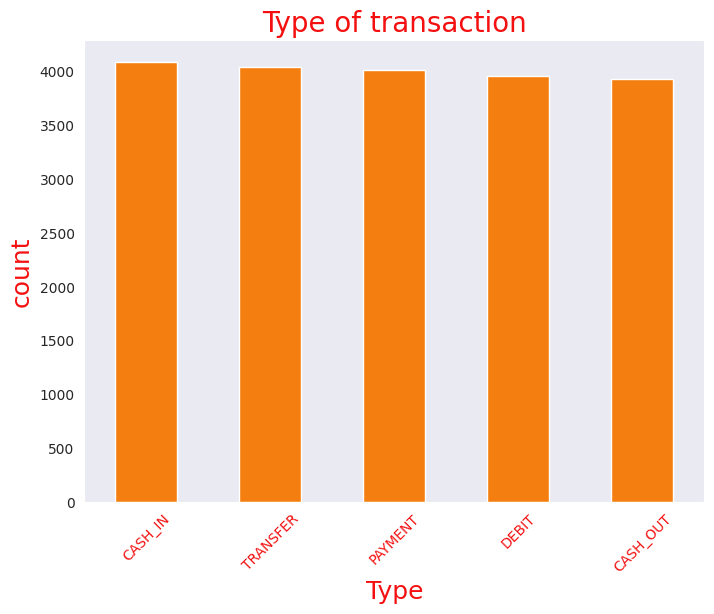

In [9]:
import pandas as pd
import matplotlib
if not hasattr(matplotlib.rcParams, '_get'): 
    matplotlib.rcParams._get = lambda key: matplotlib.rcParams.get(key)
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("dark") # set the style of the plot as dark grid
sns.set_palette("pastel")
plt.figure(figsize = (8,6))
data['type'].value_counts().plot(kind = 'bar', color = '#F47F10')
plt.title('Type of transaction', color = '#F41010', fontsize = 20)
plt.xticks(rotation = 45, color = '#F41010')
plt.xlabel('Type', fontsize = 18, color = '#F41010')
plt.ylabel('count', fontsize = 18, color = '#F41010')
plt.show()

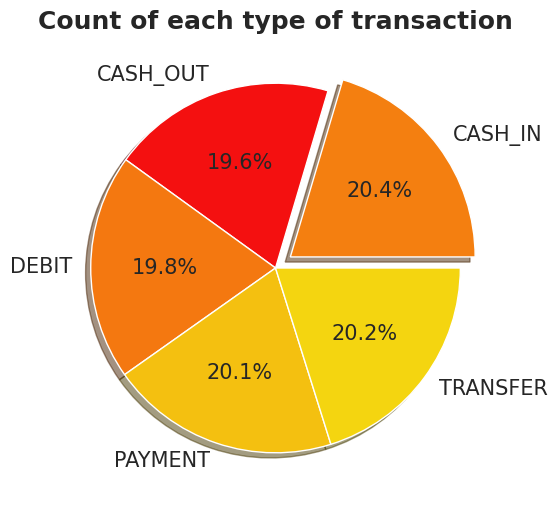

In [16]:
counts = data.groupby('type').count()['amount']
plt.figure(figsize = (6,6))
plt.pie(counts, labels = counts.index, autopct = "%1.1f%%", colors=['#F47F10', '#F41010', '#F47810', '#F4C010','#F4D510'], shadow = True,explode = (0.1, 0, 0, 0, 0),textprops={'fontsize': 15})
plt.title('Count of each type of transaction', fontweight = 'bold', fontsize = 18, fontfamily = 'DejaVu Sans')
plt.show()

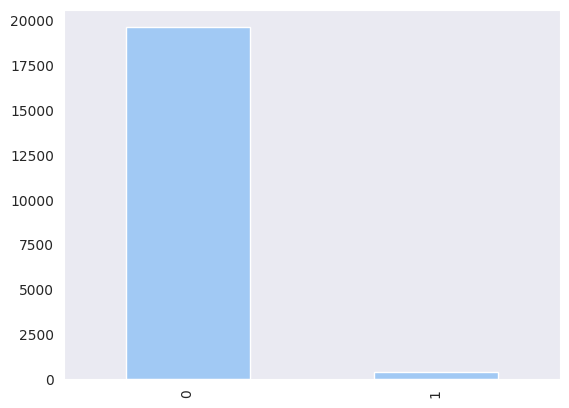

In [11]:
data['isFraud'].value_counts().plot(kind='bar')
plt.show()

In [12]:
from sklearn.model_selection import train_test_split  

X = data_new.drop(['isFraud', 'type', 'nameOrg', 'nameDest'], axis=1)
y = data_new['isFraud']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [15]:
from sklearn.ensemble import RandomForestClassifier  
from sklearn.linear_model import LogisticRegression  
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix

import mlflow
import mlflow.sklearn  

mlflow.set_tracking_uri(uri="http://127.0.0.1:5000")
mlflow.set_experiment("Fraud Detection")

def train_and_log_model(model, model_name, X_train, y_train, X_test, y_test):  
    with mlflow.start_run(run_name=model_name):  
        # Train the model  
        model.fit(X_train, y_train)  

        # Predict and calculate multiple metrics  
        predictions = model.predict(X_test)  
        
        accuracy = accuracy_score(y_test, predictions)  
        f1 = f1_score(y_test, predictions)
        precision = precision_score(y_test, predictions)
        recall = recall_score(y_test, predictions)
        
        # Get confusion matrix
        cm = confusion_matrix(y_test, predictions)
        
        # For probability predictions
        if hasattr(model, "predict_proba"):
            y_proba = model.predict_proba(X_test)[:, 1]
            auc = roc_auc_score(y_test, y_proba)
            mlflow.log_metric("auc", auc)

        # Log parameters and metrics  
        mlflow.log_param("model_name", model_name)  
        mlflow.log_metric("accuracy", accuracy)  
        mlflow.log_metric("f1_score", f1)
        mlflow.log_metric("precision", precision)
        mlflow.log_metric("recall", recall)

        # Log the model  
        mlflow.sklearn.log_model(model, artifact_path="model")  
        
        print(f"\n{model_name} Results:")
        print(f"Accuracy: {accuracy:.4f}")
        print(f"F1 Score: {f1:.4f}")
        print(f"Precision: {precision:.4f}")
        print(f"Recall: {recall:.4f}")
        print(f"Confusion Matrix:\n{cm}")

# Use class_weight='balanced' to handle imbalance
lr_model = LogisticRegression(
    max_iter=1000, 
    class_weight='balanced',  # This handles imbalance
    random_state=42
)

rf_model = RandomForestClassifier(
    n_estimators=100, 
    class_weight='balanced',  # This handles imbalance
    max_depth=10,
    random_state=42
)

# Train and log models
train_and_log_model(lr_model, "LogisticRegression_Balanced", X_train, y_train, X_test, y_test)  
train_and_log_model(rf_model, "RandomForest_Balanced", X_train, y_train, X_test, y_test)

/usr/local/lib/python3.11/site-packages/_distutils_hack/__init__.py:18: UserWarning: Distutils was imported before Setuptools, but importing Setuptools also replaces the `distutils` module in `sys.modules`. This may lead to undesirable behaviors or errors. To avoid these issues, avoid using distutils directly, ensure that setuptools is installed in the traditional way (e.g. not an editable install), and/or make sure that setuptools is always imported before distutils.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/_distutils_hack/__init__.py:33: UserWarning: Setuptools is replacing distutils.
  warnings.warn("Setuptools is replacing distutils.")



LogisticRegression_Balanced Results:
Accuracy: 0.5386
F1 Score: 0.0402
Precision: 0.0210
Recall: 0.4496
Confusion Matrix:
[[3177 2700]
 [  71   58]]

RandomForest_Balanced Results:
Accuracy: 0.8705
F1 Score: 0.0323
Precision: 0.0193
Recall: 0.1008
Confusion Matrix:
[[5215  662]
 [ 116   13]]


/usr/local/lib/python3.11/site-packages/_distutils_hack/__init__.py:18: UserWarning: Distutils was imported before Setuptools, but importing Setuptools also replaces the `distutils` module in `sys.modules`. This may lead to undesirable behaviors or errors. To avoid these issues, avoid using distutils directly, ensure that setuptools is installed in the traditional way (e.g. not an editable install), and/or make sure that setuptools is always imported before distutils.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/_distutils_hack/__init__.py:33: UserWarning: Setuptools is replacing distutils.
  warnings.warn("Setuptools is replacing distutils.")
